# JS08: Lab 3

Eksperimen hyperparameter dan evaluasi HDBSCAN.


## Langkah 0: Persiapan data sintetis

Menggunakan dataset 4 blob multiskala dari Lab 2 untuk menguji respons hyperparameter.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
import hdbscan

def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)


## Langkah 1: Eksperimen parameter min_cluster_size


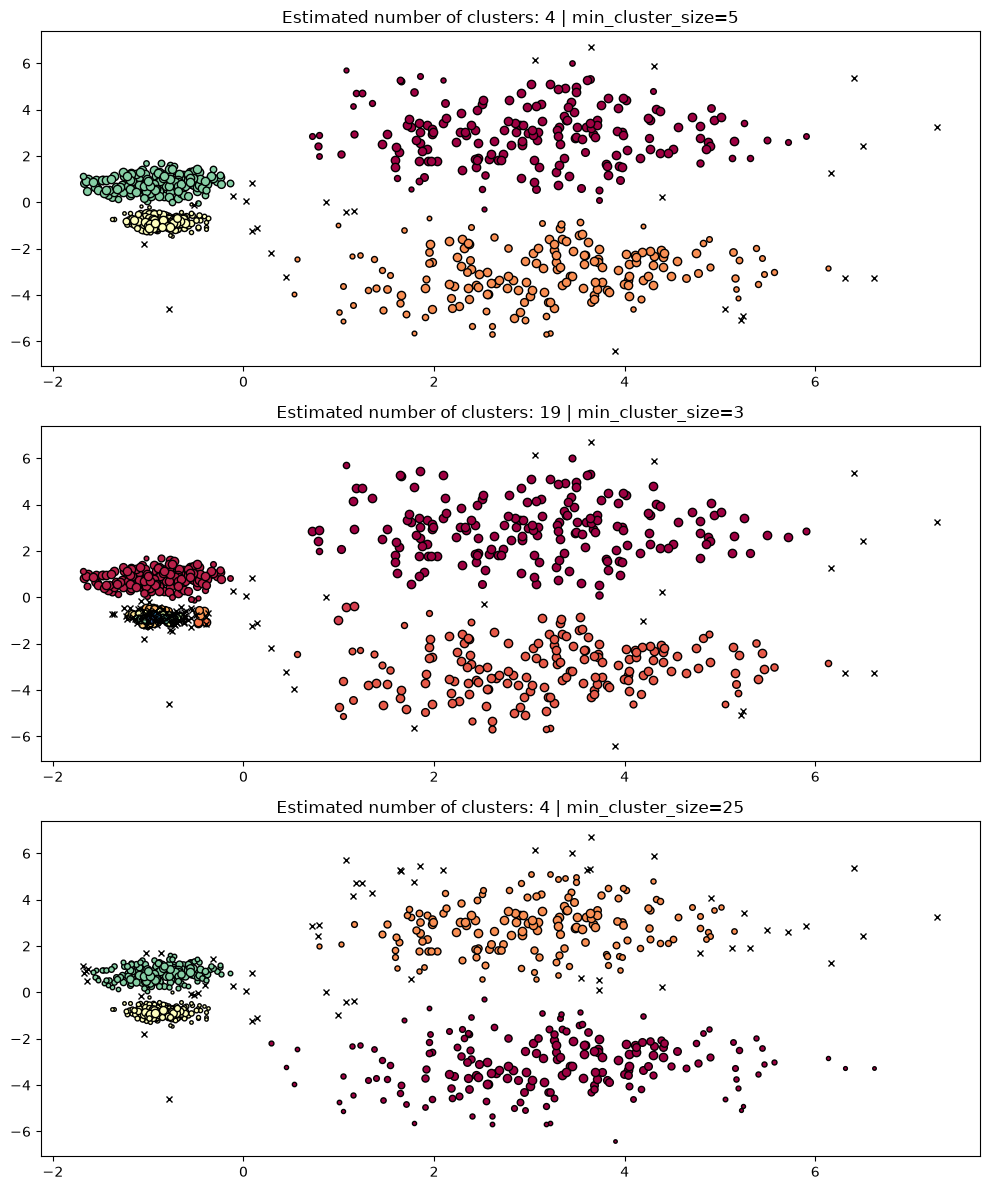

In [2]:
PARAM = (
    {"min_cluster_size": 5},
    {"min_cluster_size": 3},
    {"min_cluster_size": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])
plt.show()


## Langkah 2: Eksperimen parameter min_samples


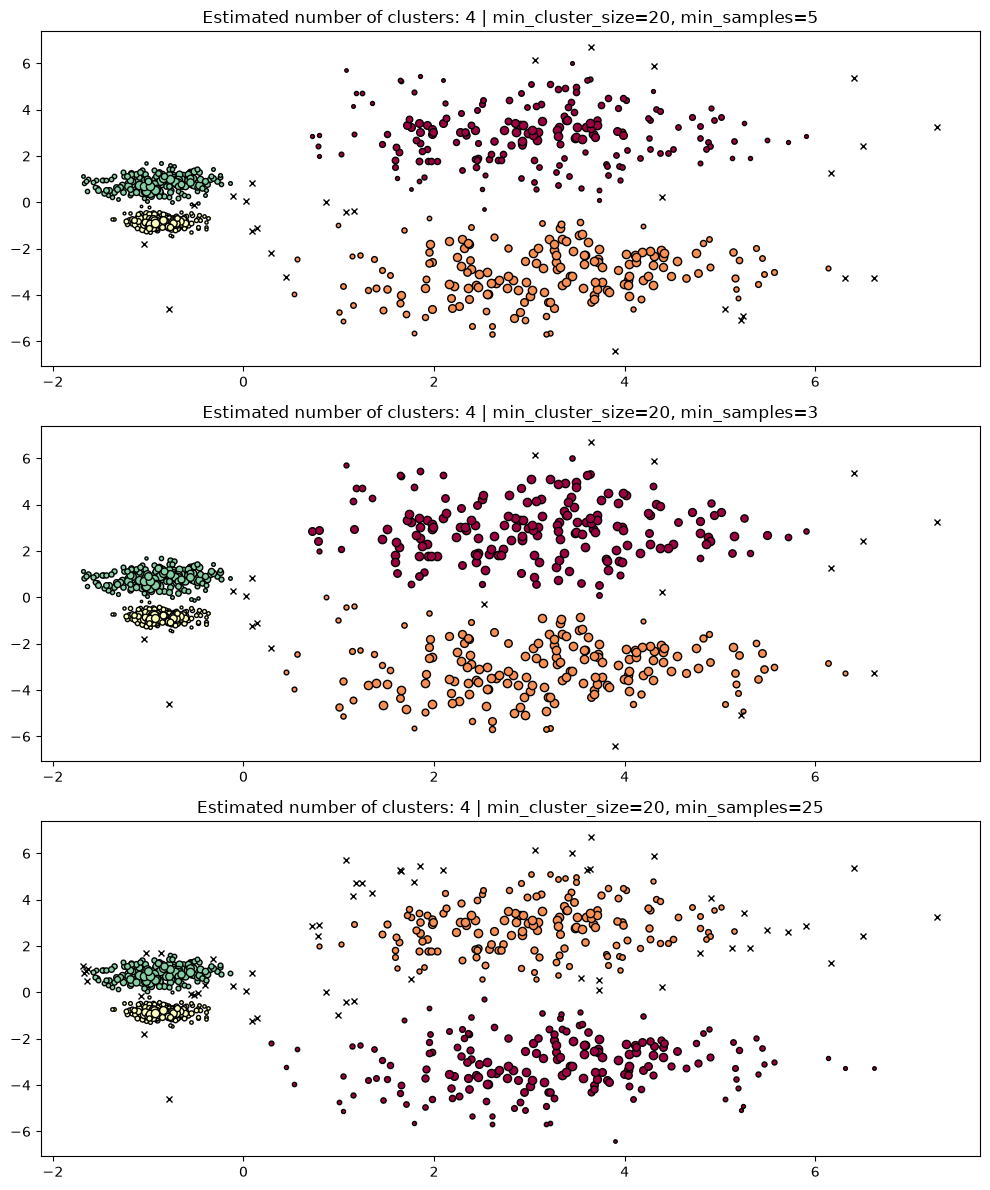

In [3]:
PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])
plt.show()


## Langkah 3: Klasterisasi DBSCAN dari pohon HDBSCAN


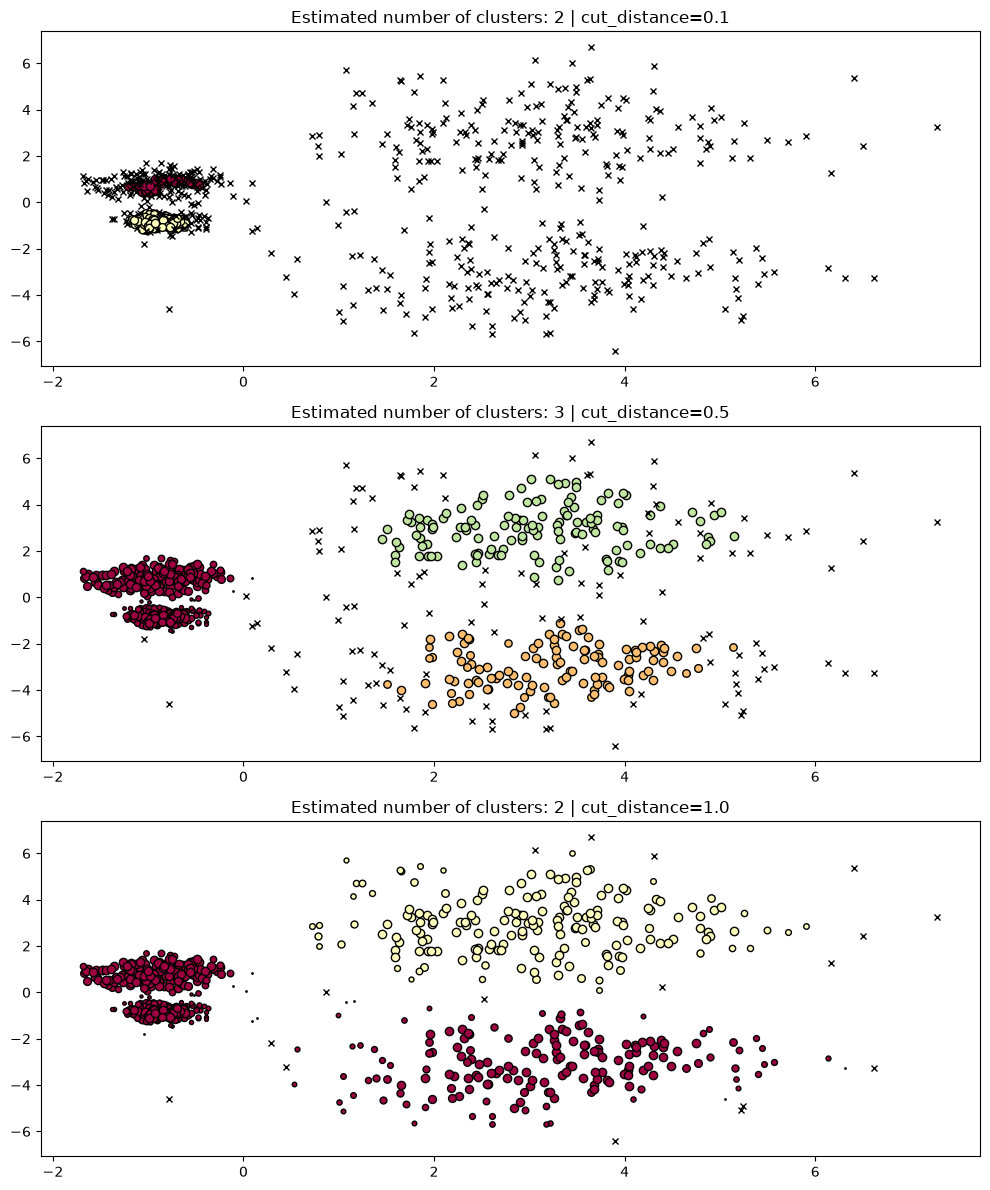

In [4]:
PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)
hdb = hdbscan.HDBSCAN().fit(X)
fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])
plt.show()


## Langkah 4: Evaluasi Silhouette Score dan DBI


In [5]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

sil_score = silhouette_score(X, hdb.labels_)
dbi_score = davies_bouldin_score(X, hdb.labels_)

print(f"Silhouette Score: {sil_score:.4f}")
print(f"Davies-Bouldin Index: {dbi_score:.4f}")


Silhouette Score: 0.5744
Davies-Bouldin Index: 1.6436


## Langkah 5: Visualisasi hasil evaluasi


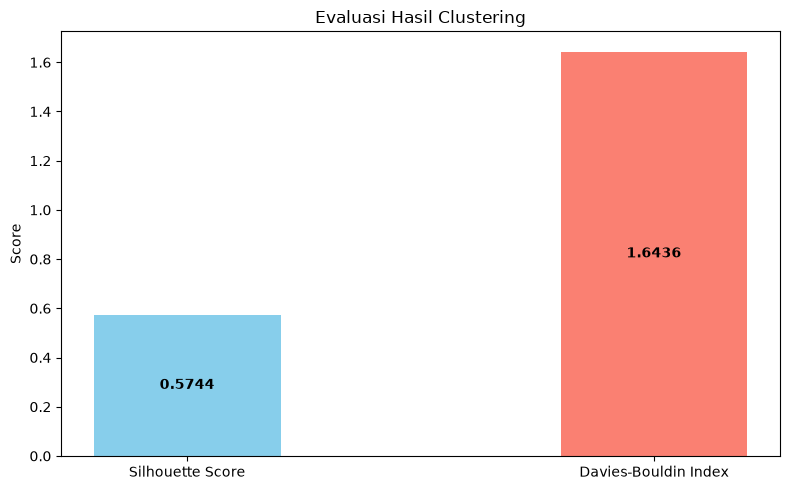

In [6]:
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'], width=0.4)
ax.set_title("Evaluasi Hasil Clustering")
ax.set_ylabel("Score")
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval / 2, f"{yval:.4f}", ha='center', va='center', color='black', fontweight='bold')
plt.tight_layout()
plt.show()


In [7]:
import pandas as pd

eval_rows = []
for p in [{"min_cluster_size": 5}, {"min_cluster_size": 15}, {"min_cluster_size": 25}]:
    m = hdbscan.HDBSCAN(**p).fit(X)
    lbl = m.labels_
    n_c = len(set(lbl) - {-1})
    sil = silhouette_score(X, lbl) if n_c >= 2 else np.nan
    dbi = davies_bouldin_score(X, lbl) if n_c >= 2 else np.nan
    eval_rows.append({
        'min_cluster_size': p['min_cluster_size'],
        'Klaster': n_c,
        'Noise': np.sum(lbl == -1),
        'Silhouette': sil,
        'DBI': dbi
    })
print(pd.DataFrame(eval_rows).to_string(index=False, float_format=lambda v: f'{v:.4f}'))


 min_cluster_size  Klaster  Noise  Silhouette    DBI
                5        4     27      0.5744 1.6436
               15        4     50      0.5563 1.7087
               25        4     60      0.5337 1.9660


## Analisis

Parameter min_cluster_size menentukan batas ukuran kelompok terkecil yang dipertahankan sebagai klaster, sedangkan min_samples mengatur seberapa ketat kriteria kepadatan lokal. Menaikkan min_samples membuat batas klaster lebih konservatif dan memperbanyak titik yang ditandai sebagai noise. Fungsi cut_distance memungkinkan kita memotong pohon hierarki HDBSCAN pada ketinggian tertentu untuk memperoleh partisi datar setara DBSCAN tanpa melatih ulang model.
